# Stitching hyperparameters: full versus reduced HMM

Read the saved pt3 experiment grid (AC 3, 5, 7, 10, 20, 40; mismatches 0/1).
This snapshot keeps pt3 independent of later minimum-size experiments.
Simulation is on the left and 1KGP on the right. Both diploid
haplotypes are included; each mean gives equal weight to each haplotype.
African means YRI in simulation and AFR in 1KGP; Non-African pools all
remaining populations, using preserved simulation annotations and pedigree labels.

In [1]:
import logging
import pathlib

import IPython.display as ipython_display
import yaml

from ch5 import nb_plot, nb_utils

repository_dir = pathlib.Path.cwd()
logger = logging.getLogger(__name__)

In [2]:
repository_dir = pathlib.Path.cwd()
config_path = {
    "experiment_config": repository_dir
    / "data/ch5/match_eval/stitching_pt3_experiment_config.yaml",
    "output_dir": repository_dir / "data/ch5/stitching_pt3_hyperparams",
    "method": "hmm",
    "workers": None,
    "baseline_partition_ac_cutoff": 10,
    "truth_comparison": {"full_hmm_cutoff": 1},
    "datasets": [
        {
            "name": "sim_n300_10mbp_error",
            "label": "Simulation",
            "population_metadata": repository_dir
            / "data/ch5/sim_n300_10mbp_error_populations.csv",
            "population_column": "population",
            "african_population": "YRI",
            "analysis_span_bp": [0, 10000000],
            "mutation_rate": 2.35e-08,
        },
        {
            "name": "tgp_n300_10mbp",
            "label": "1KGP",
            "population_metadata": repository_dir
            / "data/general/populations/tgp_3202_pedigree.csv",
            "population_column": "superpopulation",
            "african_population": "AFR",
            "analysis_span_bp": [1000000, 11000000],
            "mutation_rate": 1.29e-08,
        },
    ],
    "dating": {
        "output_subdir": "dated_args",
        "workers": None,
        "helper_threads": 1,
        "post_process": {"split_ultimate": True, "erase_flanks": True},
        "preprocess": {"delete_intervals": [], "split_disjoint": True},
        "estimation": {
            "method": "variational_gamma",
            "time_units": "generations",
            "set_metadata": True,
            "progress": False,
            "singletons_phased": True,
        },
        "compare_full_datasets": ["sim_n300_10mbp_error", "tgp_n300_10mbp"],
        "dataset_linestyles": {"sim_n300_10mbp_error": "-", "tgp_n300_10mbp": "--"},
        "frequency_bins": {
            "cutoffs": [0.01, 0.5],
            "labels": ["DAF < 0.01", "0.01 ≤ DAF < 0.5", "DAF ≥ 0.5"],
        },
    },
    "experiment_base_dir": repository_dir / "data/ch5",
}
config_path["base_dir"] = repository_dir
config = config_path
experiment_path = nb_utils.resolve_path(config["experiment_config"], repository_dir)
with experiment_path.open() as file:
    experiment = yaml.safe_load(file)
output_dir = nb_utils.resolve_path(config["output_dir"], repository_dir)
cutoffs = sorted(experiment["ac_cutoff"])
mismatch_allowances = sorted(experiment["max_mismatches"])
ac_colors = dict(
    zip(
        cutoffs,
        ["#0072B2", "#009E73", "#E69F00", "#CC79A7", "#D55E00", "#56B4E9"],
        strict=True,
    )
)
mismatch_colors = dict(zip(mismatch_allowances, ["#0072B2", "#D55E00"], strict=True))
nb_plot.configure_notebook({"figure.dpi": 120, "font.size": 10})

## Load and validate the saved runs

Each full path is compared with its stitched path in original reference
parent IDs. Saved focal masks define maximal connected focal regions and
complementary gaps independently of the copying paths. Counts and lengths
are recomputed from these inputs; earlier pt3 summaries are not used.
The independent runs are processed across available CPU cores.

In [3]:
if __name__ == "__main__":
    results = nb_utils.hyperparams_load_results(config_path, workers=config["workers"])
    comparisons = results.comparisons
    lengths = results.lengths
    output_dir.mkdir(parents=True, exist_ok=True)
    comparisons.to_csv(output_dir / "haplotype_results.csv", index=False)
    lengths.to_csv(output_dir / "region_lengths.csv", index=False)
    run_keys = ["dataset", "ac_cutoff", "max_mismatches"]
    run_summary = comparisons.groupby(run_keys).agg(
        haplotypes=("sample_id", "size"),
        individuals=("sample_id", "nunique"),
        undefined_switch_increases=(
            "switch_increase_percentage",
            lambda values: values.isna().sum(),
        ),
        empty_focal_regions=("focal_sites", lambda values: values.eq(0).sum()),
        empty_gaps=("gap_sites", lambda values: values.eq(0).sum()),
    )
    run_summary.to_csv(output_dir / "run_summary.csv")
    ipython_display.display(run_summary)

haplotypes  individuals  \
dataset              ac_cutoff max_mismatches                            
sim_n300_10mbp_error 3         0                      600          300   
                               1                      600          300   
                     5         0                      600          300   
                               1                      600          300   
                     7         0                      600          300   
                               1                      600          300   
                     10        0                      600          300   
                               1                      600          300   
                     20        0                      600          300   
                               1                      600          300   
                     40        0                      600          300   
                               1                      600          300   
tgp_n300_10mbp       3         0                      600          300   
                               1                      600          300   
                     5         0                      600          300   
                               1                      600          300   
                     7         0                      600          300   
                               1                      600          300   
                     10        0                      600          300   
                               1                      600          300   
                     20        0                      600          300   
                               1                      600          300   
                     40        0                      600          300   
                               1                      600          300   

                                               undefined_switch_increases  \
dataset              ac_cutoff max_mismatches                               
sim_n300_10mbp_error 3         0                                        0   
                               1                                        0   
                     5         0                                        0   
                               1                                        0   
                     7         0                                        0   
                               1                                        0   
                     10        0                                        0   
                               1                                        0   
                     20        0                                        0   
                               1                                        0   
                     40        0                                        0   
                               1                                        0   
tgp_n300_10mbp       3         0                                        0   
                               1                                        0   
                     5         0                                        0   
                               1                                        0   
                     7         0                                        0   
                               1                                        0   
                     10        0                                        0   
                               1                                        0   
                     20        0                                        0   
                               1                                        0   
                     40        0                                        0   
                               1                                        0   

                                               empty_focal_regions  empty_gaps  
dataset              ac_cutoff max_mis

## Extra switches vs hyper parameters

Extra switches are stitched minus full switches. Percent increases are
calculated per haplotype using full switches as denominator, then averaged.
Zero-switch full paths have undefined increases and are excluded, with counts
reported above. Hourglasses show mean ± one haplotype SEM; these describe
haplotype variability without accounting for within-individual dependence.

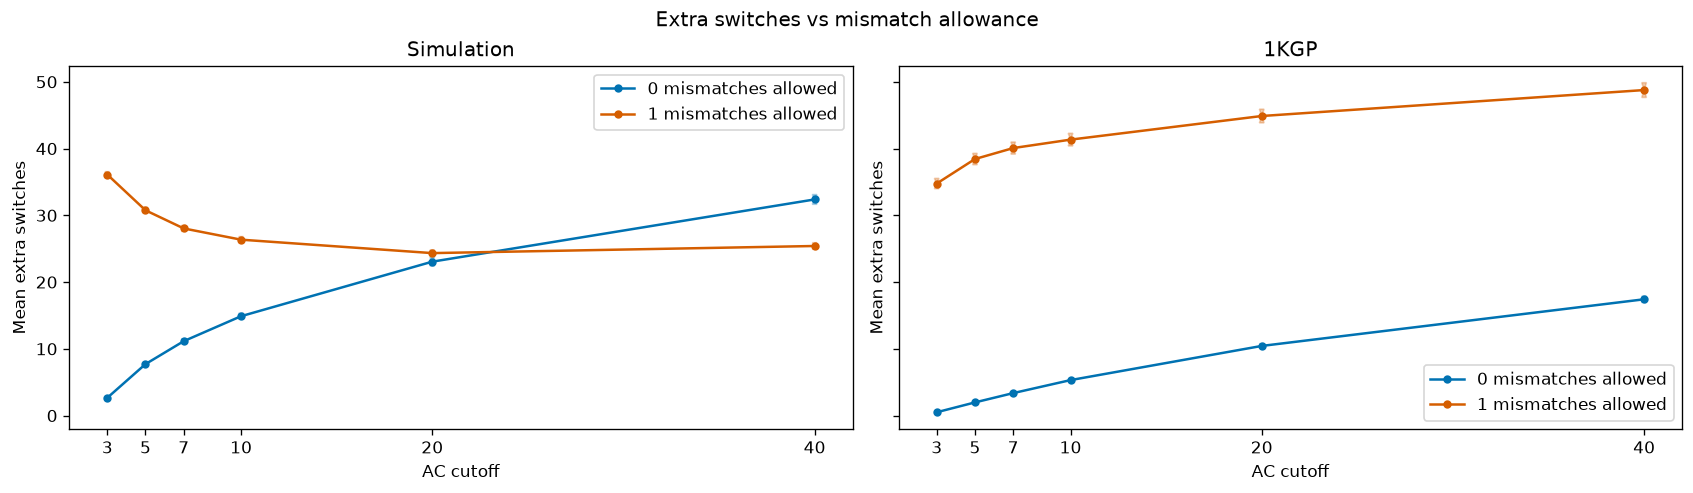

In [5]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_metric(
        "num_extra_switches",
        "Extra switches vs mismatch allowance",
        "Mean extra switches",
        comparisons=comparisons,
        config=config,
        x_values=cutoffs,
        curve_values=mismatch_allowances,
        curve_colors=mismatch_colors,
        plot_hourglass_alpha=0.3,
        plot_hourglass_width=0.12,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        x_parameter="ac_cutoff",
        curve_parameter="max_mismatches",
        x_label="AC cutoff",
        curve_label="{value} mismatches allowed",
        x_value_label="AC {value}",
    )
    nb_plot.save_figure(
        fig, "extra_switches_vs_mismatch_allowance", output_dir=output_dir
    )

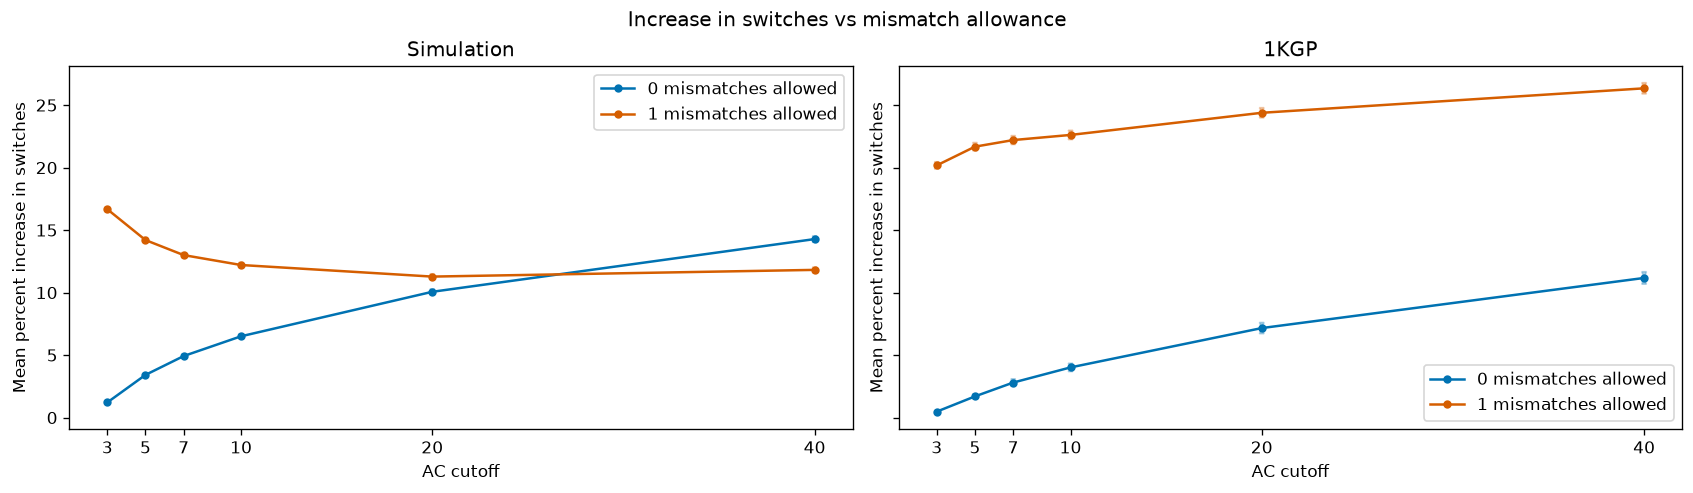

In [6]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_metric(
        "switch_increase_percentage",
        "Increase in switches vs mismatch allowance",
        "Mean percent increase in switches",
        comparisons=comparisons,
        config=config,
        x_values=cutoffs,
        curve_values=mismatch_allowances,
        curve_colors=mismatch_colors,
        plot_hourglass_alpha=0.3,
        plot_hourglass_width=0.12,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        x_parameter="ac_cutoff",
        curve_parameter="max_mismatches",
        x_label="AC cutoff",
        curve_label="{value} mismatches allowed",
        x_value_label="AC {value}",
    )
    nb_plot.save_figure(
        fig, "switch_increase_vs_mismatch_allowance", output_dir=output_dir
    )

## Focal region distributions

Coverage uses base pairs within the configured analysis window: 0–10 Mb in
simulation and 1–11 Mb in 1KGP. It uses the saved mask boundaries converted
to physical positions, clipped to these windows, rather than the retained
64 Mb chromosome span. The population curves are haplotype means.
Length distributions pool maximal focal components across all populations.
Histograms show counts; density curves are scaled by interval count and bin
width so that they overlay the same count axis. Rows show mismatch 0 and 1.
The x-axis displays through the pooled 99th percentile for each mismatch row
(configurable); each legend reports the number of intervals beyond the shown
range. KDEs use every interval, and the exported table retains the full tails.

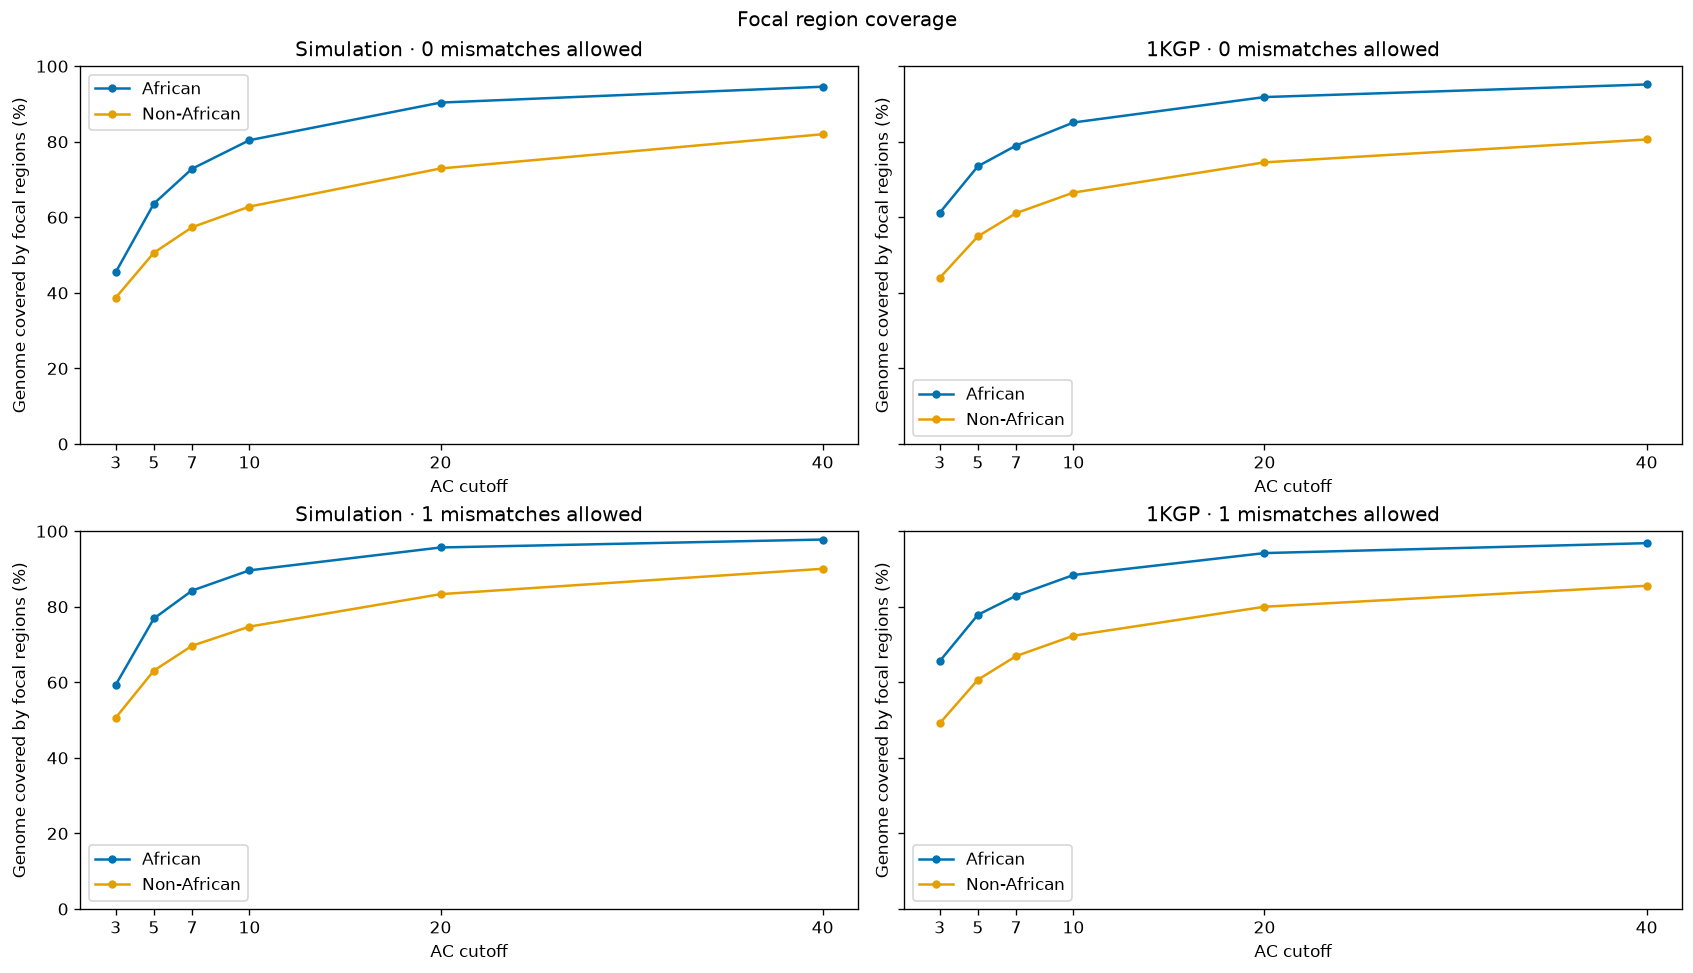

In [7]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_coverage(
        "focal",
        "Focal region coverage",
        comparisons=comparisons,
        config=config,
        x_values=cutoffs,
        curve_values=mismatch_allowances,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        plot_population_colors={"African": "#0072B2", "Non-African": "#E69F00"},
        x_parameter="ac_cutoff",
        curve_parameter="max_mismatches",
        x_label="AC cutoff",
        curve_label="{value} mismatches allowed",
        x_value_label="AC {value}",
    )
    nb_plot.save_figure(fig, "focal_region_coverage", output_dir=output_dir)

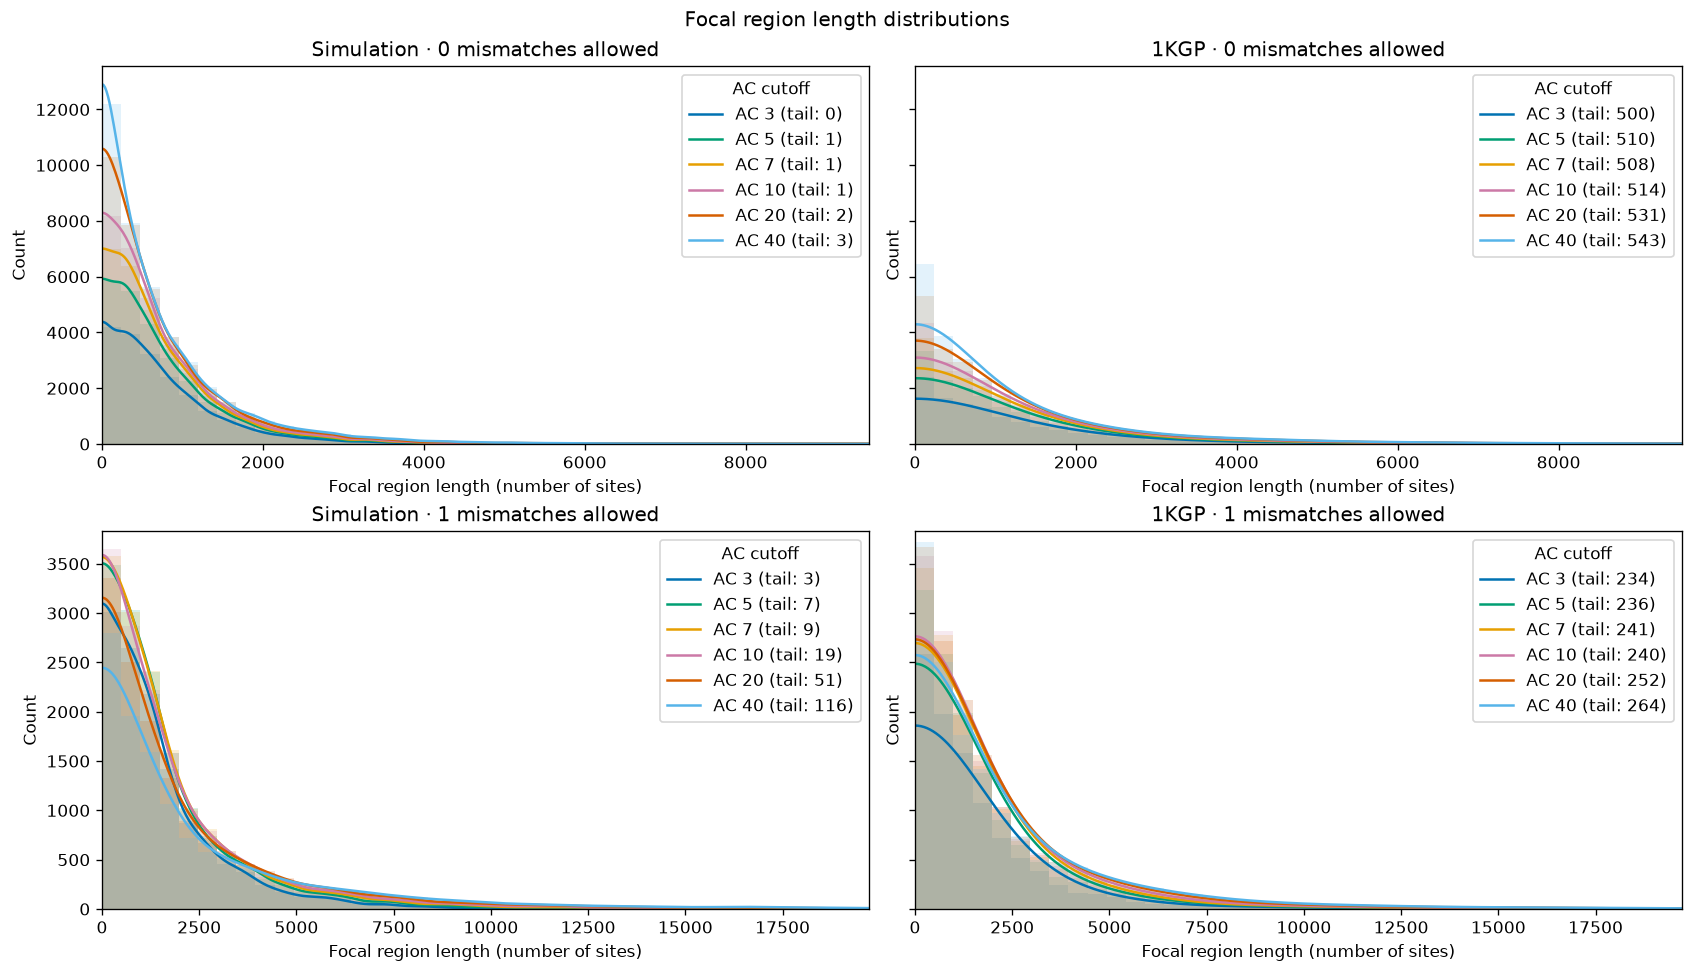

In [8]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_length_distribution(
        "focal",
        "Focal region length distributions",
        x_colors=ac_colors,
        config=config,
        x_values=cutoffs,
        lengths=lengths,
        curve_values=mismatch_allowances,
        plot_histogram_alpha=0.16,
        plot_histogram_bins=40,
        plot_kde_bandwidth="scott",
        plot_kde_grid_size=512,
        plot_length_display_quantile=0.99,
        plot_line_width=1.5,
        plot_panel_height=4,
        plot_panel_width=7,
        x_parameter="ac_cutoff",
        curve_parameter="max_mismatches",
        x_label="AC cutoff",
        curve_label="{value} mismatches allowed",
        x_value_label="AC {value}",
    )
    nb_plot.save_figure(fig, "focal_region_length_distributions", output_dir=output_dir)

## Gap distributions

Gaps are maximal complements of focal coverage. Gap coverage is the physical
complement within the same window; lengths count inference sites, including
terminal gaps. Populations, mismatch rows, histograms and density curves follow
the same definitions as the focal region plots.

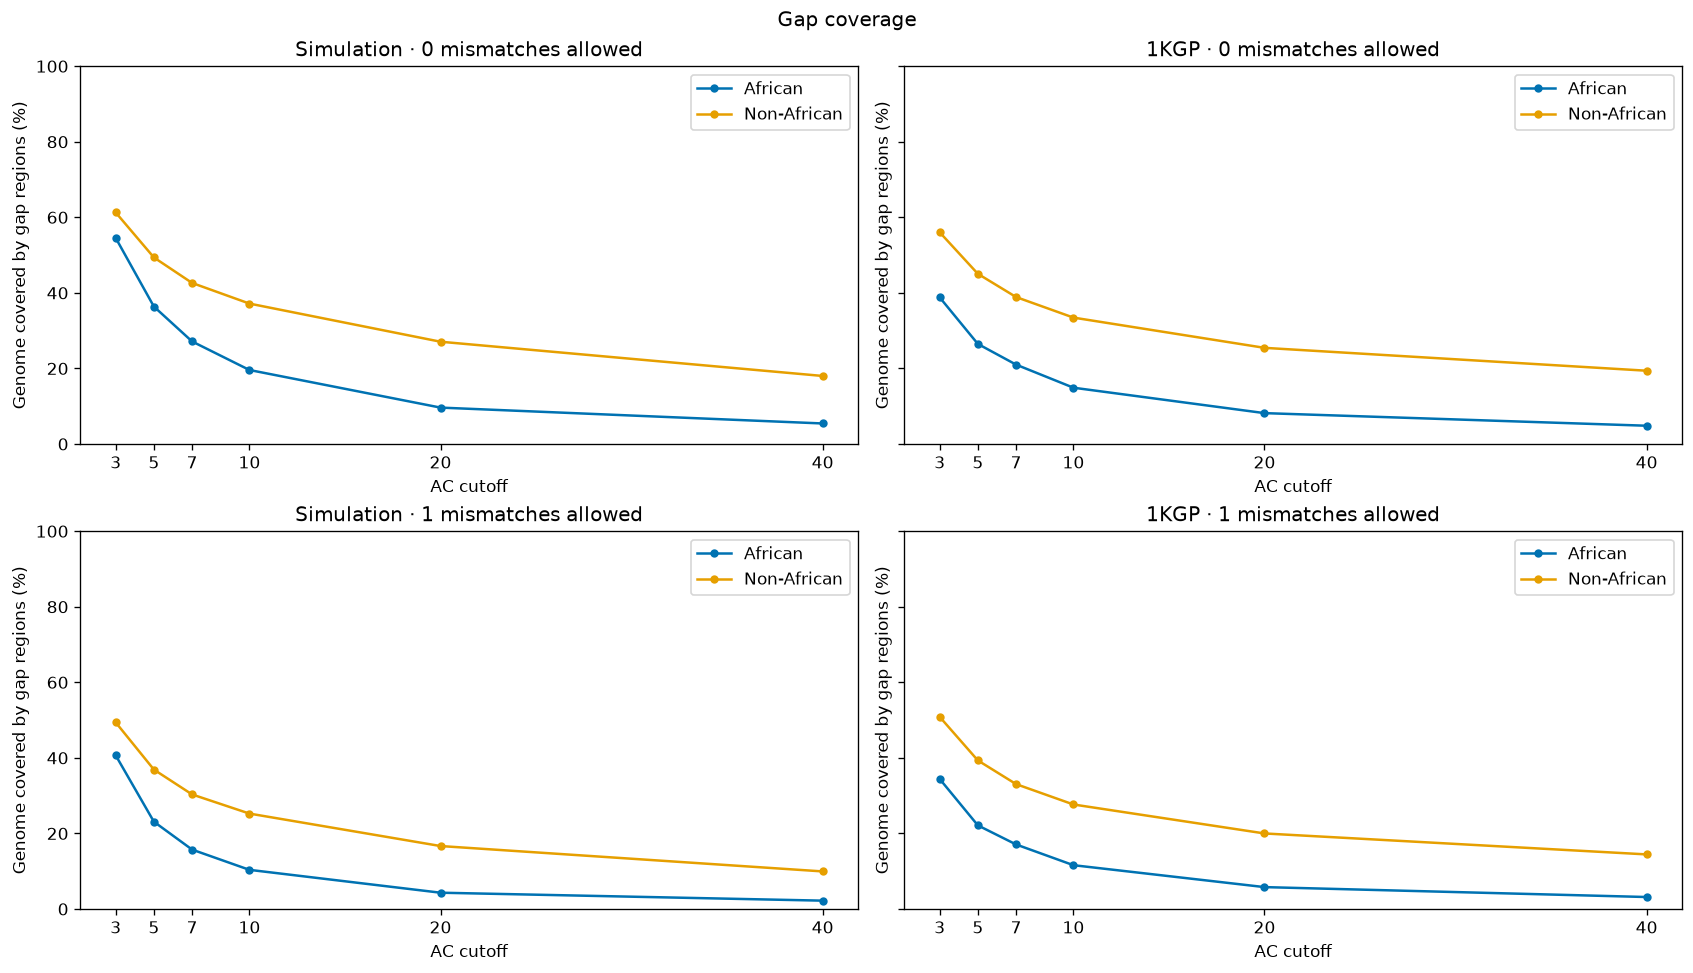

In [9]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_coverage(
        "gap",
        "Gap coverage",
        comparisons=comparisons,
        config=config,
        x_values=cutoffs,
        curve_values=mismatch_allowances,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        plot_population_colors={"African": "#0072B2", "Non-African": "#E69F00"},
        x_parameter="ac_cutoff",
        curve_parameter="max_mismatches",
        x_label="AC cutoff",
        curve_label="{value} mismatches allowed",
        x_value_label="AC {value}",
    )
    nb_plot.save_figure(fig, "gap_coverage", output_dir=output_dir)

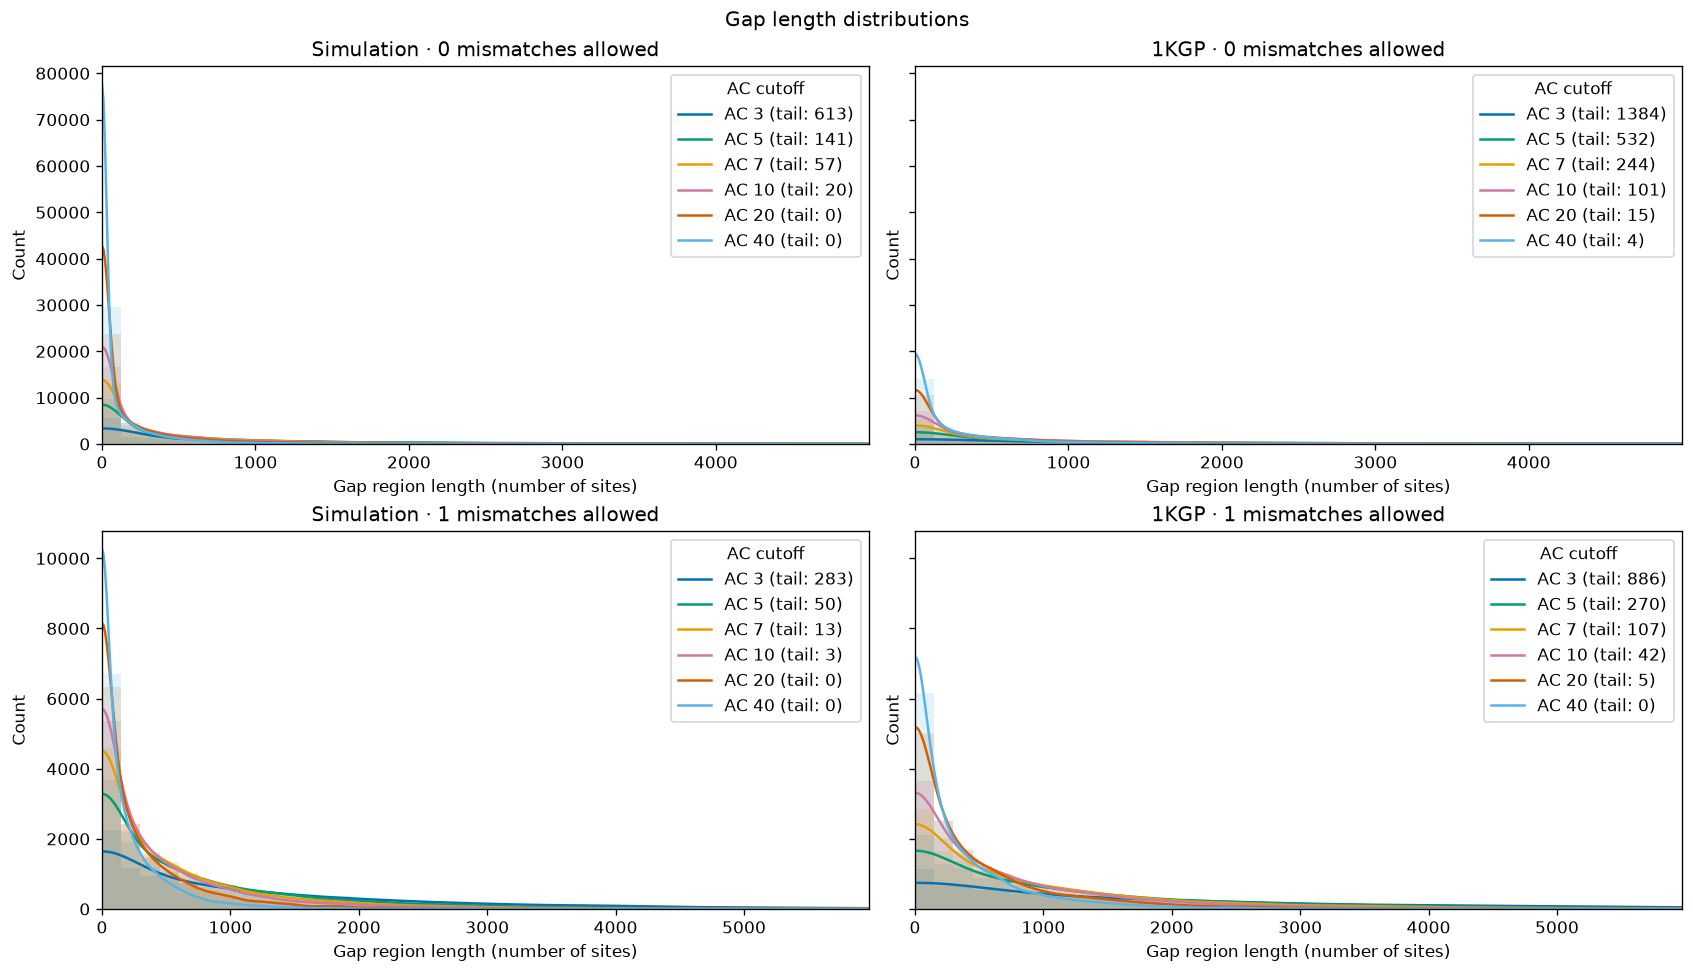

In [10]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_length_distribution(
        "gap",
        "Gap length distributions",
        x_colors=ac_colors,
        config=config,
        x_values=cutoffs,
        lengths=lengths,
        curve_values=mismatch_allowances,
        plot_histogram_alpha=0.16,
        plot_histogram_bins=40,
        plot_kde_bandwidth="scott",
        plot_kde_grid_size=512,
        plot_length_display_quantile=0.99,
        plot_line_width=1.5,
        plot_panel_height=4,
        plot_panel_width=7,
        x_parameter="ac_cutoff",
        curve_parameter="max_mismatches",
        x_label="AC cutoff",
        curve_label="{value} mismatches allowed",
        x_value_label="AC {value}",
    )
    nb_plot.save_figure(fig, "gap_length_distributions", output_dir=output_dir)

## Switch composition

Bars stack raw mean counts, from bottom to top: within focal coverage, within
gaps, and at gap seams. Switches are classified using the provenance of their
adjacent inference sites; equal parents across a seam contribute no switch.
Each stitched bar uses its own mask. Full HMM totals are invariant across AC
cutoffs, but their categories depend on the mask. The single Full HMM bar uses
**the AC 10 mask for the row's mismatch allowance**, as set in the config.

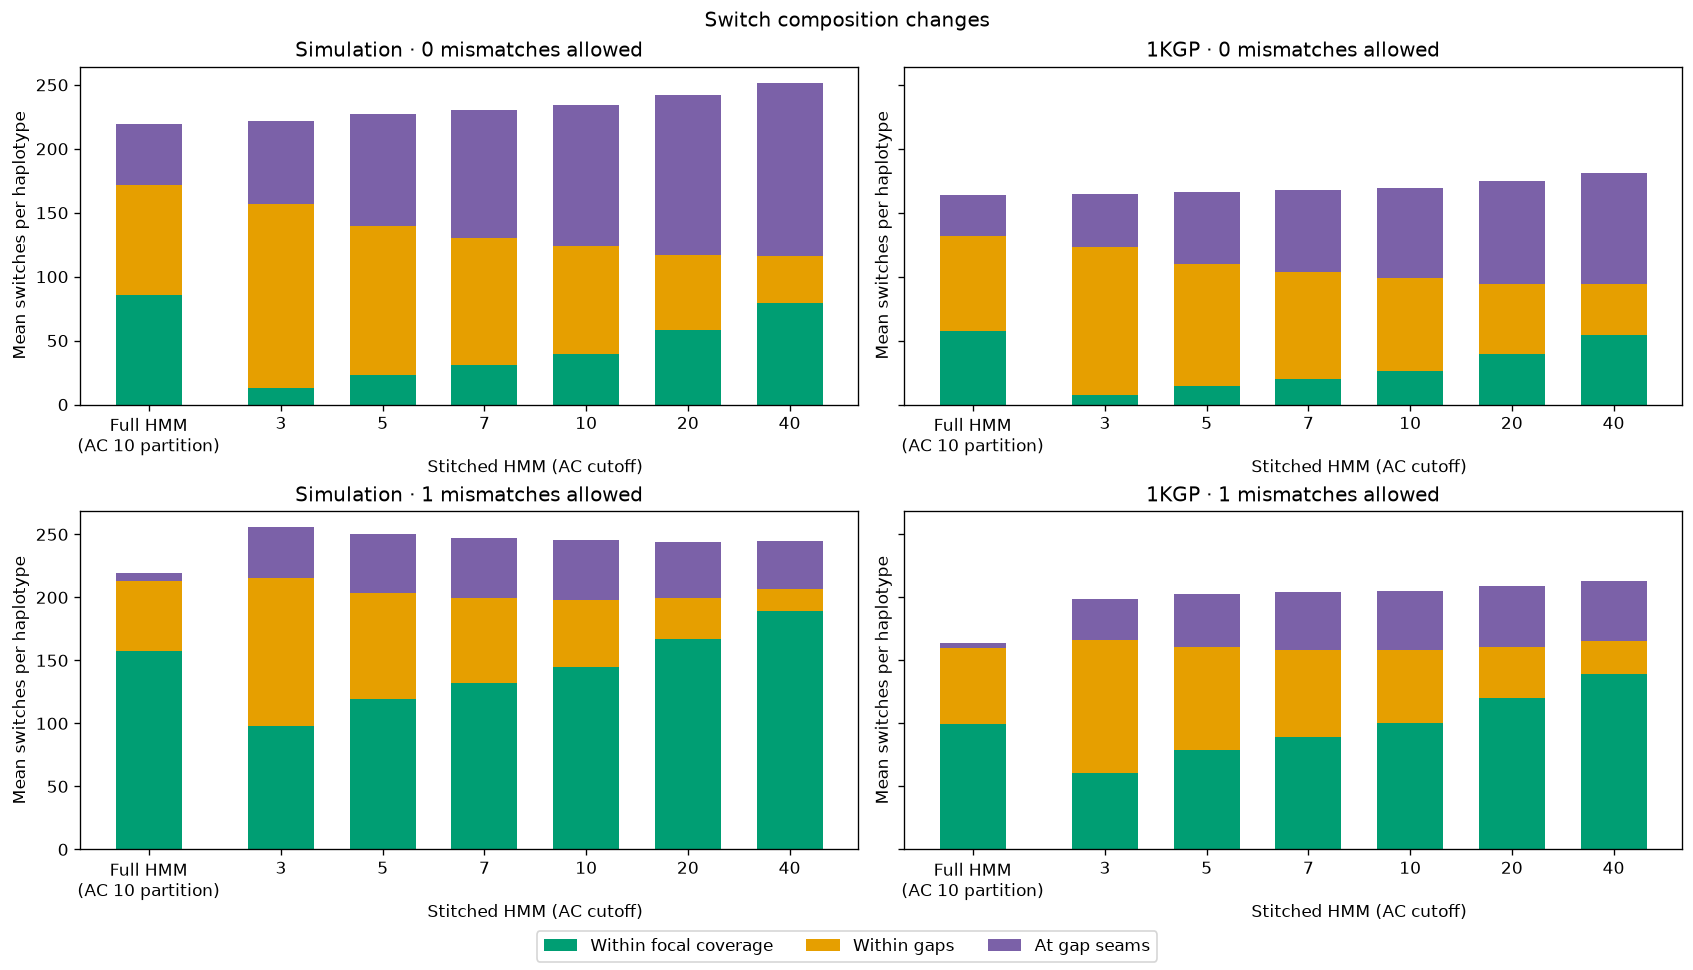

In [11]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_switch_composition(
        comparisons=comparisons,
        config=config,
        x_values=cutoffs,
        curve_values=mismatch_allowances,
        plot_bar_width=0.65,
        plot_full_stitched_gap_bar_widths=1,
        plot_group_label_y=-0.2,
        plot_panel_height=4,
        plot_panel_width=7,
        plot_switch_categories=["focal", "gap", "seam"],
        plot_switch_colors=["#009E73", "#E69F00", "#7B61A8"],
        plot_switch_labels=["Within focal coverage", "Within gaps", "At gap seams"],
        x_parameter="ac_cutoff",
        curve_parameter="max_mismatches",
        x_label="AC cutoff",
        curve_label="{value} mismatches allowed",
        x_value_label="AC {value}",
    )
    nb_plot.save_figure(fig, "switch_composition_changes", output_dir=output_dir)

## Parent agreement

Agreement compares original reference parent IDs at inference sites, using
only sites within the named region as denominator. Percentages are averaged
across haplotypes, pooling populations; empty regions are excluded and counted
in the run summary. Hourglasses use the same mean ± SEM helper as switch plots.

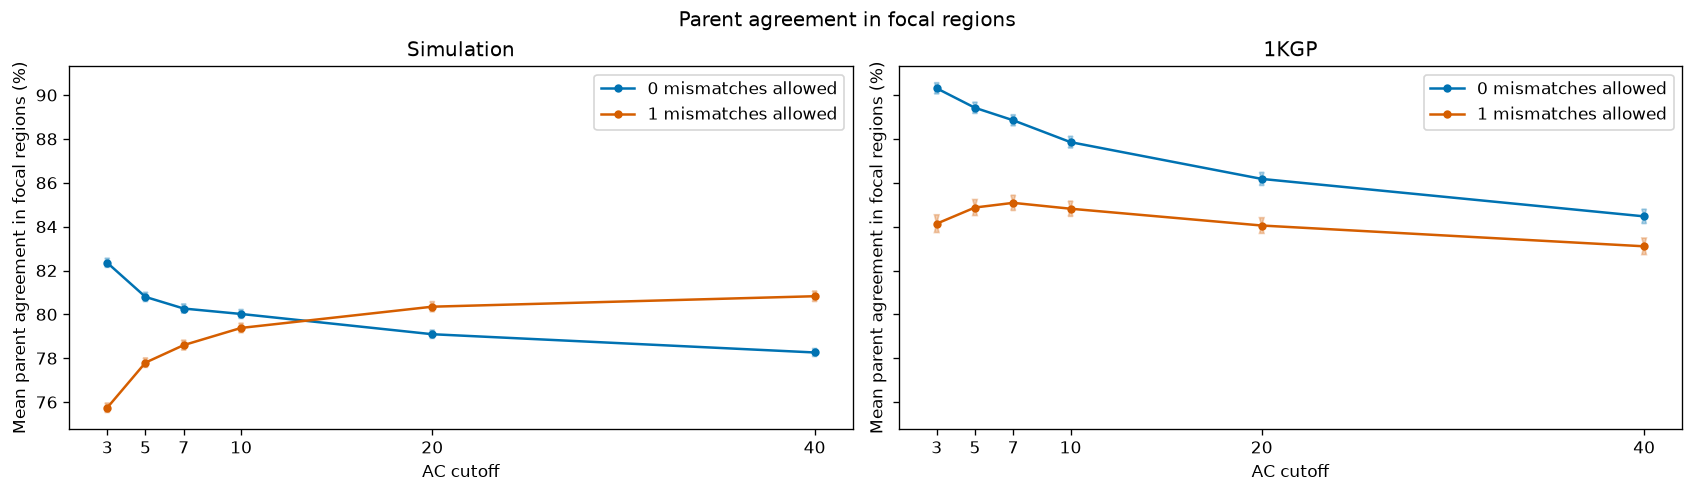

In [12]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_metric(
        "focal_agreement_percentage",
        "Parent agreement in focal regions",
        "Mean parent agreement in focal regions (%)",
        comparisons=comparisons,
        config=config,
        x_values=cutoffs,
        curve_values=mismatch_allowances,
        curve_colors=mismatch_colors,
        plot_hourglass_alpha=0.3,
        plot_hourglass_width=0.12,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        x_parameter="ac_cutoff",
        curve_parameter="max_mismatches",
        x_label="AC cutoff",
        curve_label="{value} mismatches allowed",
        x_value_label="AC {value}",
    )
    nb_plot.save_figure(fig, "parent_agreement_in_focal_regions", output_dir=output_dir)

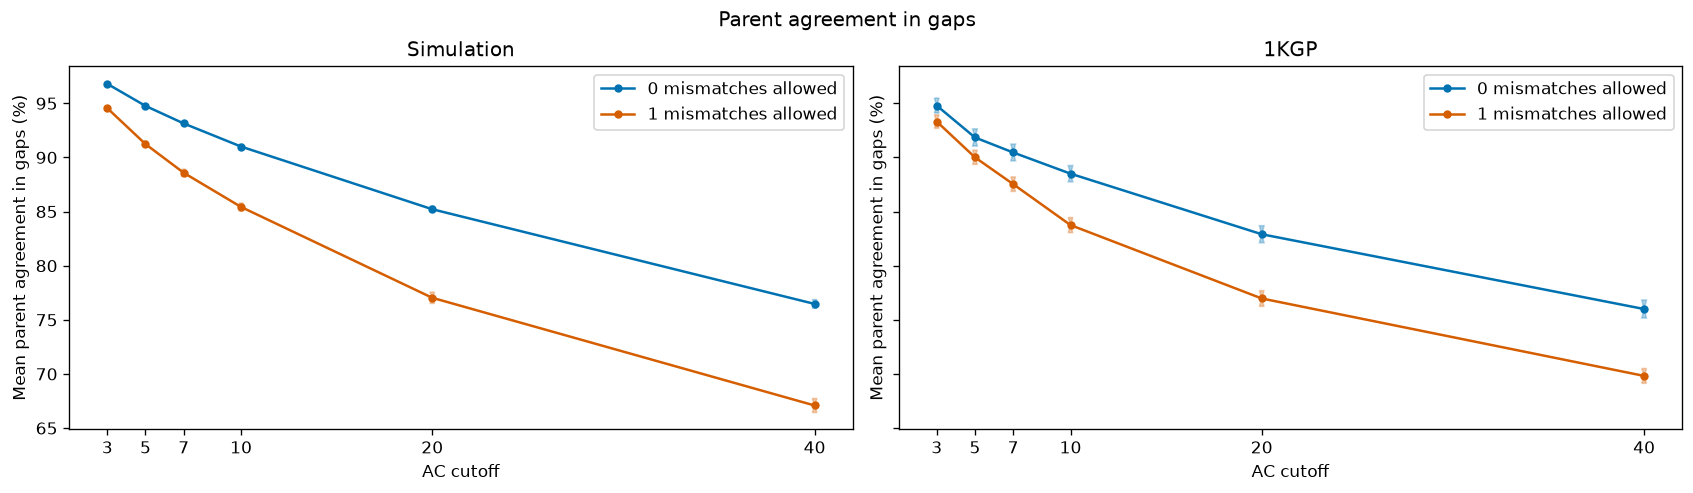

In [13]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_metric(
        "gap_agreement_percentage",
        "Parent agreement in gaps",
        "Mean parent agreement in gaps (%)",
        comparisons=comparisons,
        config=config,
        x_values=cutoffs,
        curve_values=mismatch_allowances,
        curve_colors=mismatch_colors,
        plot_hourglass_alpha=0.3,
        plot_hourglass_width=0.12,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        x_parameter="ac_cutoff",
        curve_parameter="max_mismatches",
        x_label="AC cutoff",
        curve_label="{value} mismatches allowed",
        x_value_label="AC {value}",
    )
    nb_plot.save_figure(fig, "parent_agreement_in_gaps", output_dir=output_dir)

## Tree sequence comparisons

Load both Full HMM outputs and every stitched matched
output in the current parameter grid. Edge and tree counts describe the
**raw saved tree sequences**, including their reference ancestry and retained
chromosome coordinates. Plot stitched minus Full HMM counts against AC
cutoff: edge differences in the first row and tree differences in the second.
Simulation is on the left and 1KGP on the right; colour identifies mismatch
allowance. Negative values mean stitching produces fewer edges or trees.

In [14]:
if __name__ == "__main__":
    tree_sequences = nb_utils.hyperparams_load_tree_sequences(config_path)
    ts_statistics = tree_sequences.statistics
    ts_differences = nb_utils.tree_statistic_differences(ts_statistics)
    ts_statistics.to_csv(output_dir / "ts_statistics.csv", index=False)
    ts_differences.to_csv(output_dir / "ts_statistic_differences.csv", index=False)
    ipython_display.display(ts_differences)

,dataset,method,ac_cutoff,max_mismatches,num_edges,num_trees,num_edges_full,num_trees_full,num_edges_difference,num_trees_difference
1,sim_n300_10mbp_error,stitched,3.0,0.0,595754,51587,594161,52861,1593,-1274
2,sim_n300_10mbp_error,stitched,3.0,1.0,615830,52150,594161,52861,21669,-711
3,sim_n300_10mbp_error,stitched,5.0,0.0,598787,52149,594161,52861,4626,-712
4,sim_n300_10mbp_error,stitched,5.0,1.0,612615,52629,594161,52861,18454,-232
5,sim_n300_10mbp_error,stitched,7.0,0.0,600849,52440,594161,52861,6688,-421
6,sim_n300_10mbp_error,stitched,7.0,1.0,610983,52815,594161,52861,16822,-46
7,sim_n300_10mbp_error,stitched,10.0,0.0,603094,52710,594161,52861,8933,-151
8,sim_n300_10mbp_error,stitched,10.0,1.0,609972,52925,594161,52861,15811,64
9,sim_n300_10mbp_error,stitched,20.0,0.0,607995,53155,594161,52861,13834,294
10,sim_n300_10mbp_error,stitched,20.0,1.0,608765,53019,594161,52861,14604,158


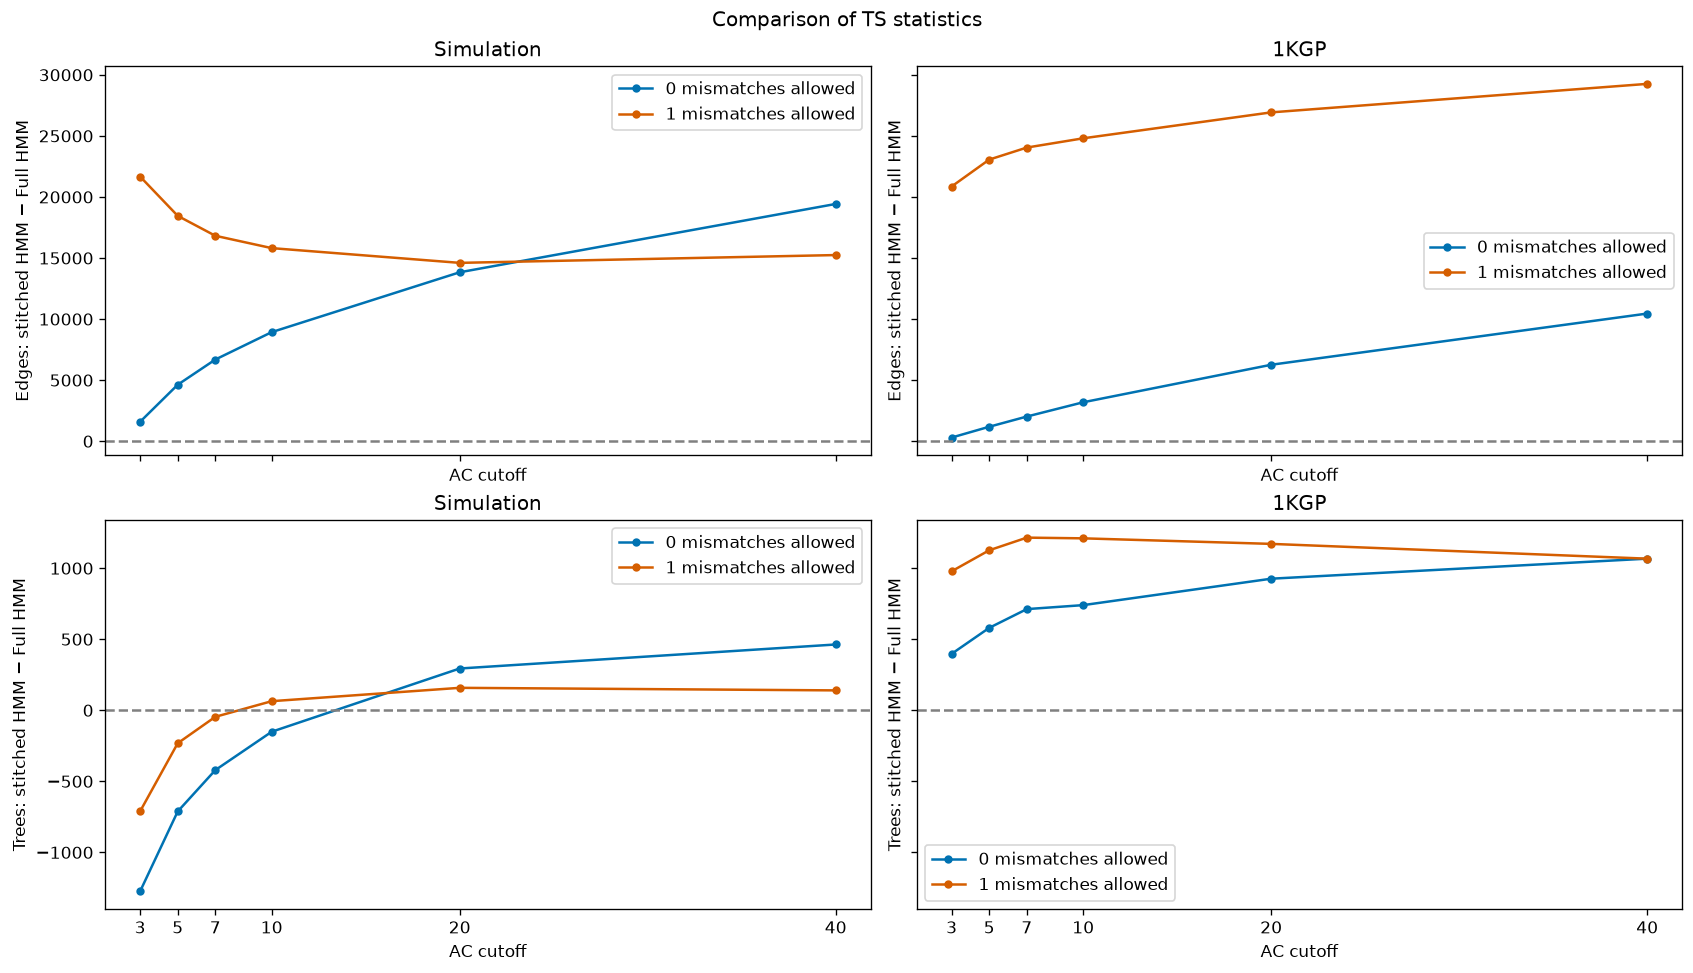

In [15]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_statistic_differences(
        config=config,
        x_values=cutoffs,
        curve_values=mismatch_allowances,
        curve_colors=mismatch_colors,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        ts_differences=ts_differences,
        x_parameter="ac_cutoff",
        curve_parameter="max_mismatches",
        x_label="AC cutoff",
        curve_label="{value} mismatches allowed",
        x_value_label="AC {value}",
    )
    nb_plot.save_figure(fig, "comparison_of_ts_statistics", output_dir=output_dir)

### Comparing ARG metrics

Compare each stitched output with its dataset's Full HMM output using
[tscompare.haplotype_arf](https://tskit.dev/tscompare/docs/stable/api.html#tscompare.haplotype_arf).
The stitched sequence is the first argument and Full HMM is the second:
ARF is the fraction of stitched node span unsupported by Full HMM (lower is
better); TPR is the fraction of Full HMM node span represented by stitching
(higher is better). Rows show ARF and TPR; columns show simulation and
1KGP. Colour identifies mismatch allowance, with two lines in every panel.

Haplotypes are aligned by `(sample_id, ploidy_index)` in matched-node metadata.
Both sequences are restricted to the dataset's 10 Mb window,
translated to shared coordinates and simplified in the same sample
order, retaining unary ancestors for node-span comparisons.
Missing terminal ancestry is retained within the explicit window.

**Interpretation reminder:** ARF = 0.135 at AC 3 / zero mismatches means
13.5% of stitched node span is not represented in Full HMM; lower is better.
TPR = 0.853 means 85.3% of Full HMM node span is represented in the stitched
result; higher is better. Their denominators belong to different ARGs.

In [16]:
if __name__ == "__main__":
    arg_comparisons = nb_utils.hyperparams_arg_metrics(
        tree_sequences, config["datasets"], workers=config["workers"]
    )
    arg_comparisons.to_csv(output_dir / "arg_metrics.csv", index=False)
    ipython_display.display(arg_comparisons)

,dataset,ac_cutoff,max_mismatches,arf,tpr,comparison_method,reference_method,comparison_time_units,reference_time_units
0,sim_n300_10mbp_error,3,0,0.135038,0.852919,stitched_hmm,full_hmm,unknown,unknown
1,sim_n300_10mbp_error,3,1,0.198294,0.797216,stitched_hmm,full_hmm,unknown,unknown
2,sim_n300_10mbp_error,5,0,0.162078,0.815636,stitched_hmm,full_hmm,unknown,unknown
3,sim_n300_10mbp_error,5,1,0.207619,0.784440,stitched_hmm,full_hmm,unknown,unknown
4,sim_n300_10mbp_error,7,0,0.173767,0.798982,stitched_hmm,full_hmm,unknown,unknown
5,sim_n300_10mbp_error,7,1,0.208432,0.781691,stitched_hmm,full_hmm,unknown,unknown
6,sim_n300_10mbp_error,10,0,0.182052,0.787341,stitched_hmm,full_hmm,unknown,unknown
7,sim_n300_10mbp_error,10,1,0.205400,0.783460,stitched_hmm,full_hmm,unknown,unknown
8,sim_n300_10mbp_error,20,0,0.191061,0.772526,stitched_hmm,full_hmm,unknown,unknown
9,sim_n300_10mbp_error,20,1,0.195750,0.791161,stitched_hmm,full_hmm,unknown,unknown


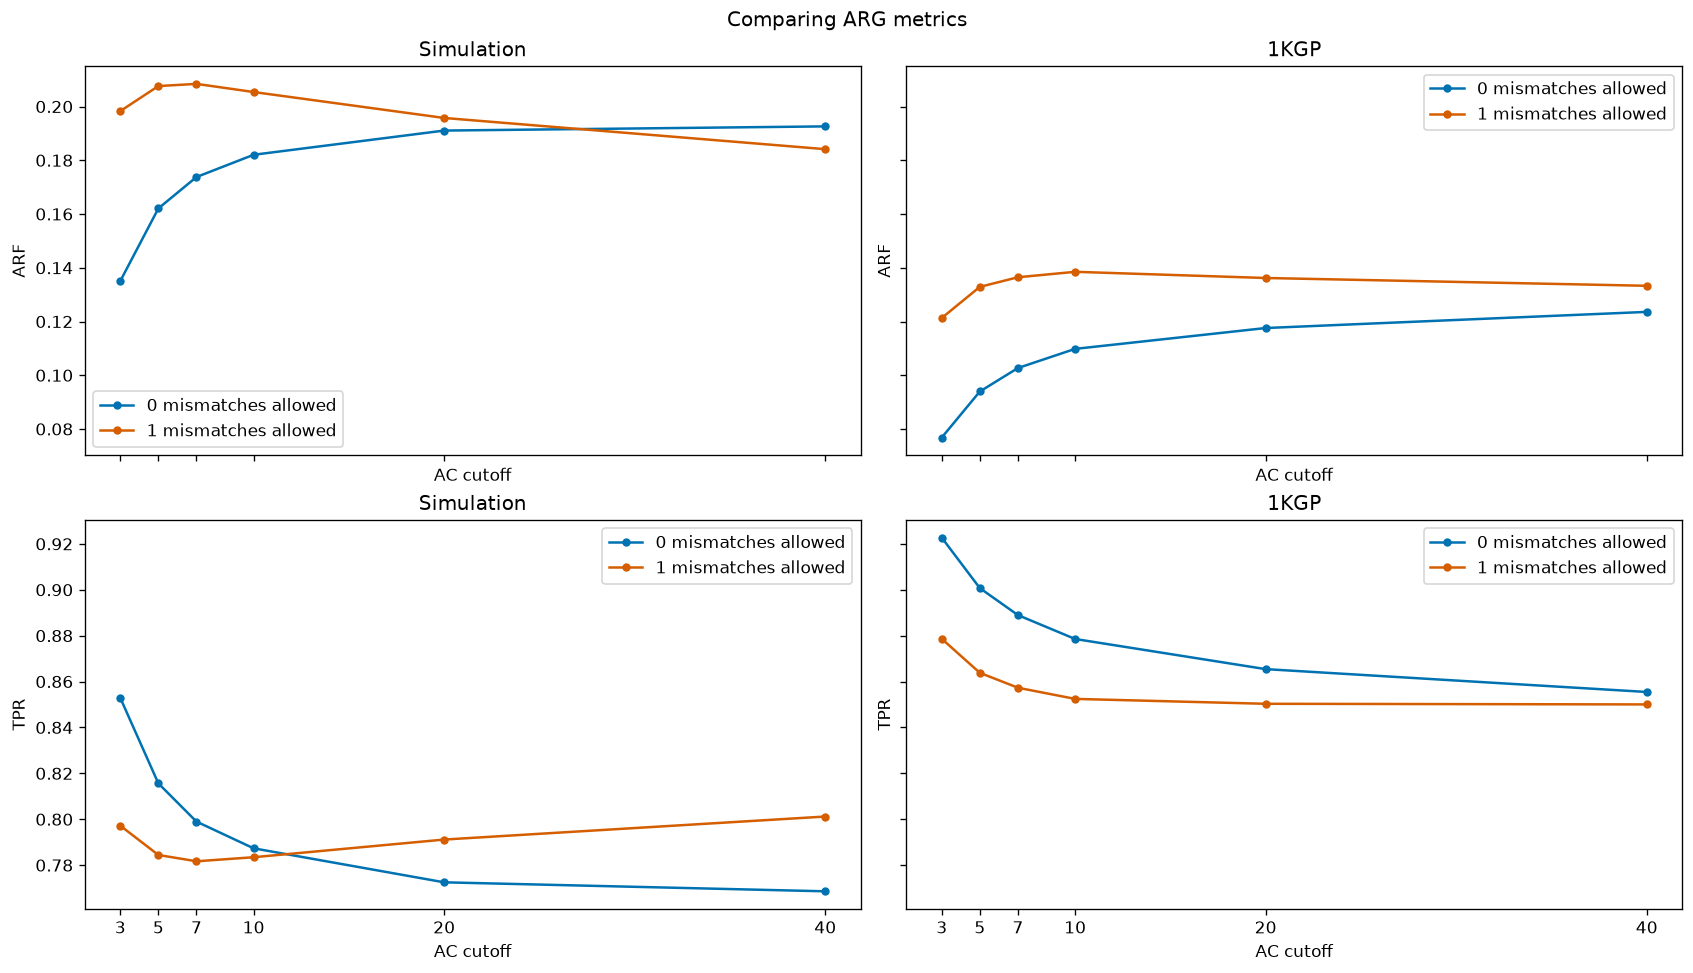

In [17]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_arg_metrics(
        arg_comparisons=arg_comparisons,
        config=config,
        x_values=cutoffs,
        curve_values=mismatch_allowances,
        curve_colors=mismatch_colors,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        x_parameter="ac_cutoff",
        curve_parameter="max_mismatches",
        x_label="AC cutoff",
        curve_label="{value} mismatches allowed",
        x_value_label="AC {value}",
    )
    nb_plot.save_figure(fig, "comparing_arg_metrics", output_dir=output_dir)

## ARG metrics against the true simulated tree sequence

Compare the simulation's Full HMM and each stitched output with the true ARG.
Align truth's VCF haplotype identities to the matched-node metadata and use
the same 0–10 Mb window, retaining unary ancestors. The columns show ARF and
TPR; colour identifies mismatch allowance. The Full HMM baseline is placed
at **1 (Full HMM)** for display, and has no actual AC cutoff or mismatch setting.

Here ARF is the proportion of the matched output's node span not represented
in truth; TPR is the proportion of true node span represented in that output.
Lower ARF and higher TPR indicate greater agreement with the true ARG.
Each y-axis zooms to the observed values to make small differences visible.

In [18]:
if __name__ == "__main__":
    truth_comparisons = nb_utils.hyperparams_truth_arg_metrics(
        tree_sequences, config_path, workers=config["workers"]
    )
    truth_comparisons.to_csv(output_dir / "arg_metrics_against_truth.csv", index=False)
    ipython_display.display(truth_comparisons)

,dataset,ac_cutoff,max_mismatches,arf,tpr,comparison_method,reference_method,comparison_time_units,reference_time_units
0,sim_n300_10mbp_error,1,NaN,0.373512,0.532529,full_hmm,true_arg,unknown,generations
1,sim_n300_10mbp_error,3,0.0,0.373087,0.541009,stitched_hmm,true_arg,unknown,generations
2,sim_n300_10mbp_error,3,1.0,0.375531,0.546156,stitched_hmm,true_arg,unknown,generations
3,sim_n300_10mbp_error,5,0.0,0.371002,0.539461,stitched_hmm,true_arg,unknown,generations
4,sim_n300_10mbp_error,5,1.0,0.373853,0.542392,stitched_hmm,true_arg,unknown,generations
5,sim_n300_10mbp_error,7,0.0,0.369324,0.538821,stitched_hmm,true_arg,unknown,generations
6,sim_n300_10mbp_error,7,1.0,0.372123,0.541192,stitched_hmm,true_arg,unknown,generations
7,sim_n300_10mbp_error,10,0.0,0.367482,0.538252,stitched_hmm,true_arg,unknown,generations
8,sim_n300_10mbp_error,10,1.0,0.370599,0.540109,stitched_hmm,true_arg,unknown,generations
9,sim_n300_10mbp_error,20,0.0,0.364108,0.537331,stitched_hmm,true_arg,unknown,generations


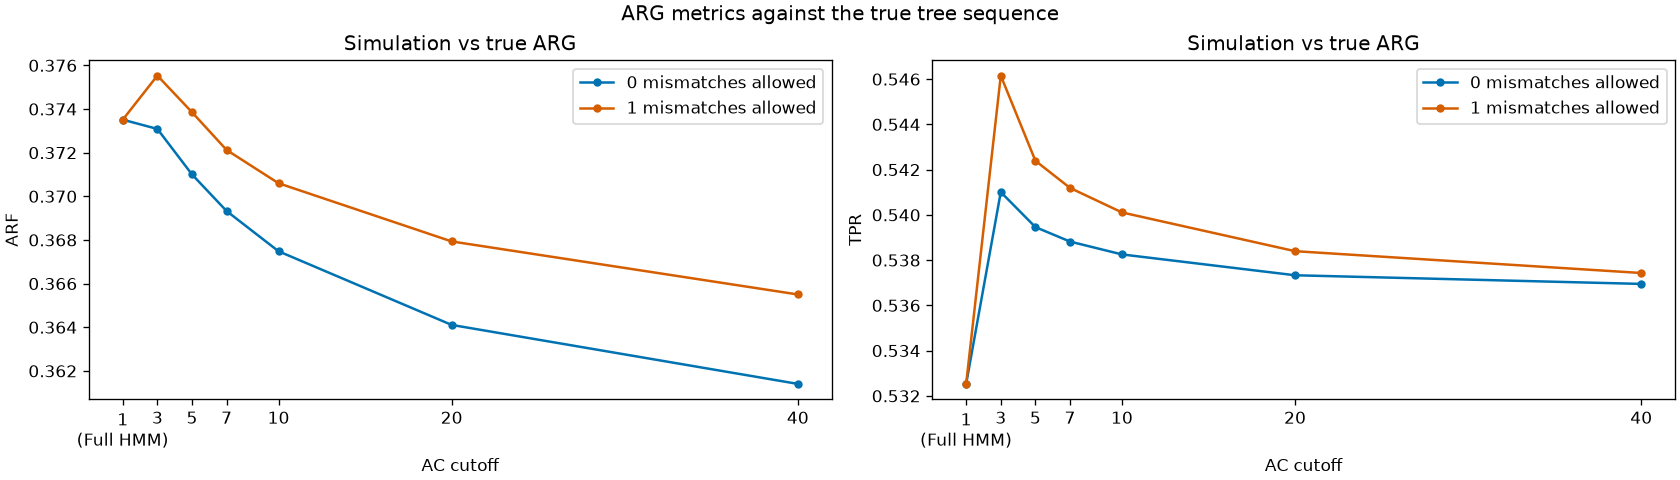

In [19]:
if __name__ == "__main__":
    fig = nb_plot.plot_parameter_truth_arg_metrics(
        x_values=cutoffs,
        curve_values=mismatch_allowances,
        curve_colors=mismatch_colors,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=4,
        plot_panel_width=7,
        truth_comparisons=truth_comparisons,
        x_parameter="ac_cutoff",
        curve_parameter="max_mismatches",
        x_label="AC cutoff",
        curve_label="{value} mismatches allowed",
        x_value_label="AC {value}",
        baseline_x=1,
        stitched_method="stitched_hmm",
    )
    nb_plot.save_figure(fig, "arg_metrics_against_truth", output_dir=output_dir)

## Mutation-age correlations after dating

All 26 inferred ARGs (Full HMM and twelve reduced-HMM cases per dataset) are
post-processed with the updated local tsinfer. Singleton and other omitted
sites are restored from the observed sample VCZ, retaining the inferred
topology and observed alleles. The analysed window is retained, then
`tsdate.preprocess_ts` splits disjoint nodes before `tsdate.date` uses the
variational-gamma method. Dated ARGs and input/settings manifests are saved
under `dated_args`; unchanged results are reused on subsequent runs.

Mutation rates are 2.35 × 10⁻⁸ per bp per generation for the simulation
(from its mutation provenance), and a configured 1.29 × 10⁻⁸ for 1KGP.
Singletons retain their observed phase. See the
[tsdate dating and preprocessing documentation](https://tskit.dev/tsdate/docs/stable/usage.html).

**These plots compare mutation ages, not node ages.** Inferred ages are
tsdate's posterior mutation means (`mutation.metadata['mn']`), rather than
branch-midpoint times in the mutation table. Truth uses the simulated
mutation event times. Mutations are paired by genomic position and identical
ancestral/derived states. Sites with zero or multiple mutations, or nonfinite
ages, are excluded. Each panel/dataset uses one common set across all its
cases, so the plotted correlations are directly comparable. The CSV reports
the number of matched mutations. Correlations are unweighted Pearson r on
ages in generations, conditional on this common unambiguous mutation set.

Left: simulation Full HMM and all reduced-HMM cases against true ages.
Right: reduced HMM against the dated Full HMM. Colour indicates mismatch
allowance; line style indicates dataset. AC cutoff varies on the x-axis;
the left panel adds a separate Full HMM category.

In [4]:
if __name__ == "__main__":
    dated_runs = nb_utils.dating_date_all(config_path)
    dated_runs.to_csv(output_dir / "dated_arg_summary.csv", index=False)
    mutation_age_results = nb_utils.dating_mutation_correlations(
        dated_runs, config_path
    )
    mutation_age_results.to_csv(
        output_dir / "mutation_age_correlations.csv", index=False
    )
    ipython_display.display(
        mutation_age_results.loc[mutation_age_results.frequency_bin.eq("all")]
    )

,dataset,comparison_method,ac_cutoff,min_focal_region_size,max_mismatches,reference_method,frequency_bin,matched_mutations,pearson_r,mean_estimated_age,mean_reference_age,mean_error_generations,median_absolute_error_generations
0,sim_n300_10mbp_error,stitched_hmm,3.0,None,0.0,full_hmm,all,84765,0.933722,3780.652133,3679.333983,101.318150,26.861832
1,sim_n300_10mbp_error,stitched_hmm,3.0,None,1.0,full_hmm,all,84765,0.864272,3842.112505,3679.333983,162.778522,54.114149
2,sim_n300_10mbp_error,stitched_hmm,5.0,None,0.0,full_hmm,all,84765,0.915740,3814.836833,3679.333983,135.502850,34.691835
3,sim_n300_10mbp_error,stitched_hmm,5.0,None,1.0,full_hmm,all,84765,0.885377,3857.772580,3679.333983,178.438597,68.279433
4,sim_n300_10mbp_error,stitched_hmm,7.0,None,1.0,full_hmm,all,84765,0.874656,3891.163507,3679.333983,211.829524,76.297726
5,sim_n300_10mbp_error,stitched_hmm,7.0,None,0.0,full_hmm,all,84765,0.900667,3853.029765,3679.333983,173.695781,39.771757
6,sim_n300_10mbp_error,stitched_hmm,10.0,None,0.0,full_hmm,all,84765,0.886359,3865.073424,3679.333983,185.739440,44.275260
7,sim_n300_10mbp_error,stitched_hmm,10.0,None,1.0,full_hmm,all,84765,0.889134,3900.427740,3679.333983,221.093756,80.680397
8,sim_n300_10mbp_error,stitched_hmm,20.0,None,1.0,full_hmm,all,84765,0.888811,3909.303775,3679.333983,229.969791,83.473667
9,sim_n300_10mbp_error,stitched_hmm,20.0,None,0.0,full_hmm,all,84765,0.884850,3868.400630,3679.333983,189.066646,52.425858


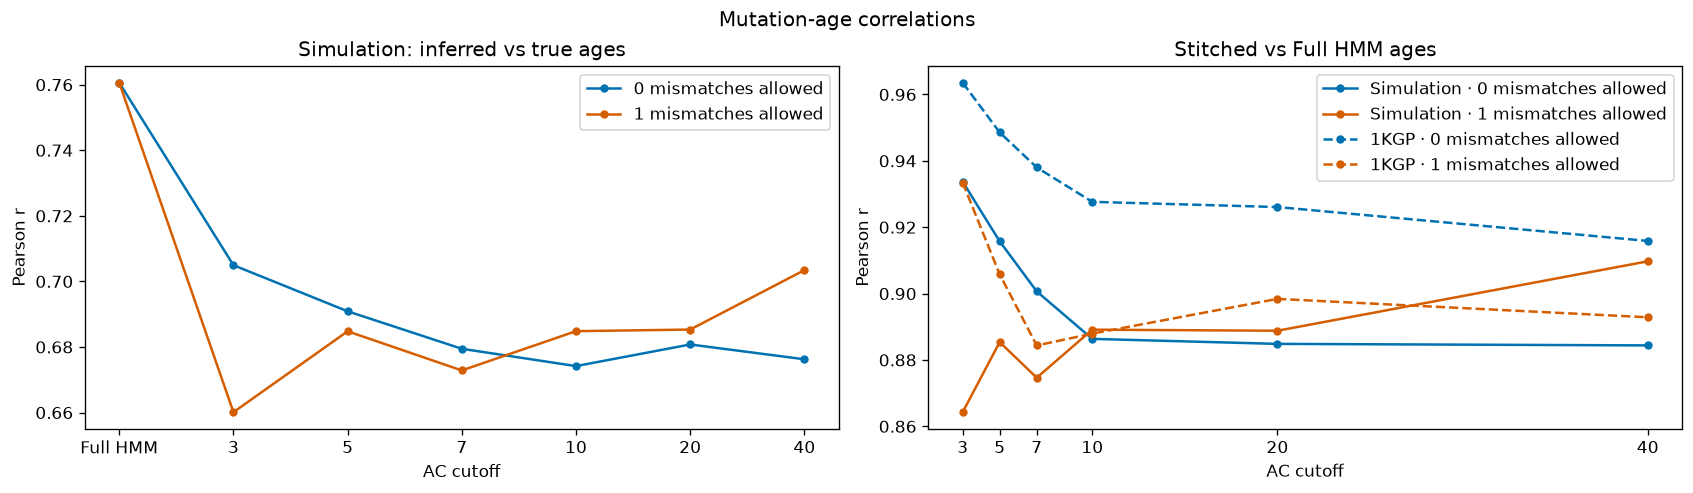

In [5]:
if __name__ == "__main__":
    fig = nb_plot.correlation_figure(
        mutation_age_results,
        config,
        experiment,
        curve_colors=["#0072B2", "#D55E00"],
        curve_label="{value} mismatches allowed",
        curve_parameter="max_mismatches",
        dataset_linestyles={"sim_n300_10mbp_error": "-", "tgp_n300_10mbp": "--"},
        line_width=1.5,
        marker_size=4,
        panel_height=4,
        panel_width=7,
        x_label="AC cutoff",
        x_parameter="ac_cutoff",
    )
    nb_plot.save_figure(fig, "mutation_age_correlations", output_dir=output_dir)

## Mutation-age correlations by derived allele frequency

The three rows split observed derived allele frequency (DAF) into
**DAF < 0.01**, **0.01 ≤ DAF < 0.5**, and **DAF ≥ 0.5**. Boundaries enter
the upper bin. Frequencies are measured among the 600 sample haplotypes in
the dated Full HMM, and that bin assignment is held fixed for every case in
both panels. These are derived frequencies, rather than minor frequencies.
Each row repeats the overall truth and Full HMM comparisons on that subset;
the same shared-mutation and posterior-mean rules apply. Within-bin Pearson r
can be lower simply because conditioning on frequency restricts the age range.

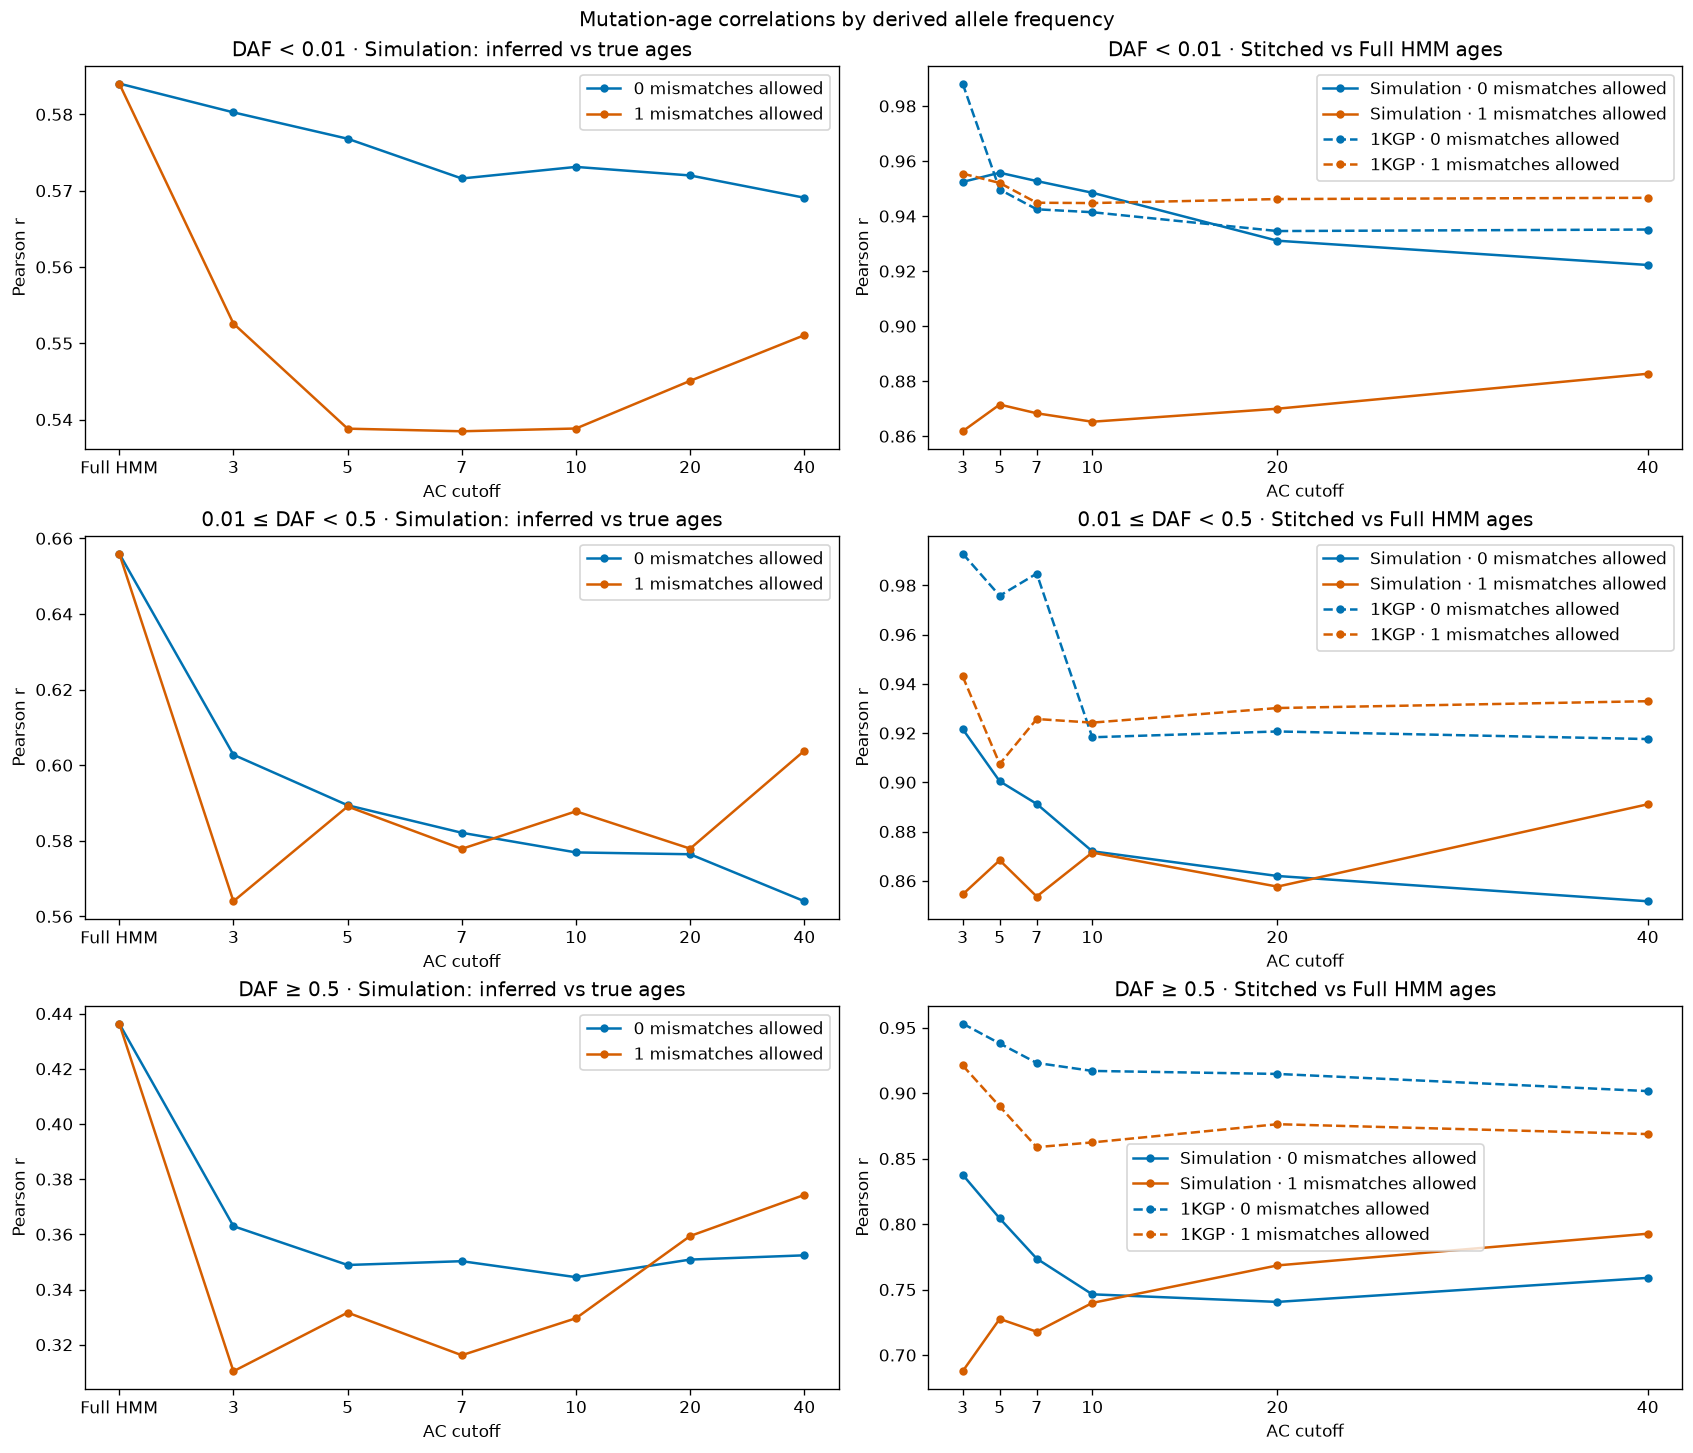

In [6]:
if __name__ == "__main__":
    fig = nb_plot.correlation_figure(
        mutation_age_results,
        config,
        experiment,
        split_frequency=True,
        curve_colors=["#0072B2", "#D55E00"],
        curve_label="{value} mismatches allowed",
        curve_parameter="max_mismatches",
        dataset_linestyles={"sim_n300_10mbp_error": "-", "tgp_n300_10mbp": "--"},
        line_width=1.5,
        marker_size=4,
        panel_height=4,
        panel_width=7,
        x_label="AC cutoff",
        x_parameter="ac_cutoff",
    )
    nb_plot.save_figure(
        fig, "mutation_age_correlations_by_frequency", output_dir=output_dir
    )

## Full HMM versus stitched mutation-age densities

These density scatterplots compare **Full HMM posterior mutation ages on the
x-axis** with **stitched posterior mutation ages on the y-axis**, across
**all allele frequencies**. Simulation and 1KGP each have a separate grid.
Columns follow the parameter on the line plots' x-axis; rows follow their
coloured curves. Every panel within a dataset uses the same common mutation
set as the overall Full HMM correlation panel, with identical axes, bins and
colour scale. Ages and mutation counts both use logarithmic scales; the
dashed line marks equal ages. Annotated Pearson r uses ages in generations
before log transformation. No simulation truth or frequency filtering enters
these comparisons.

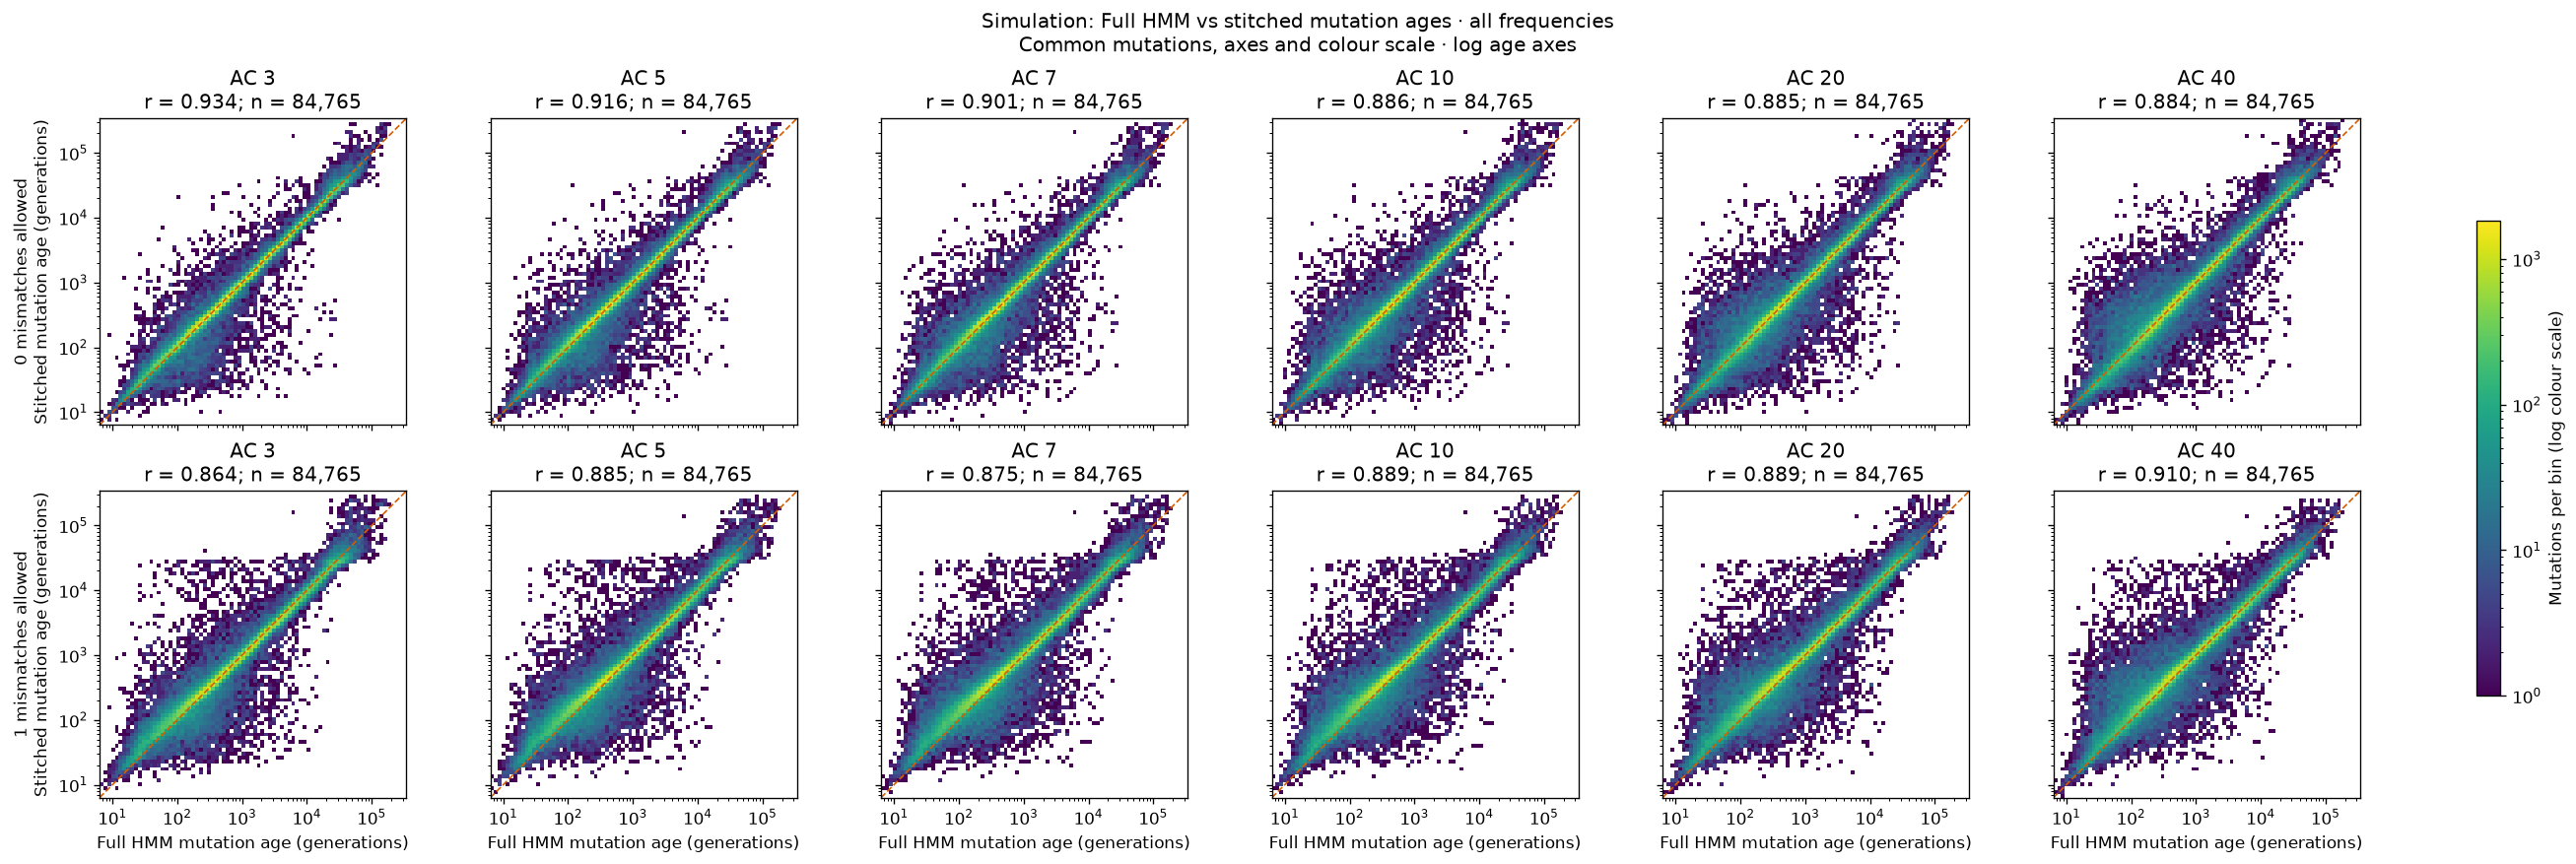

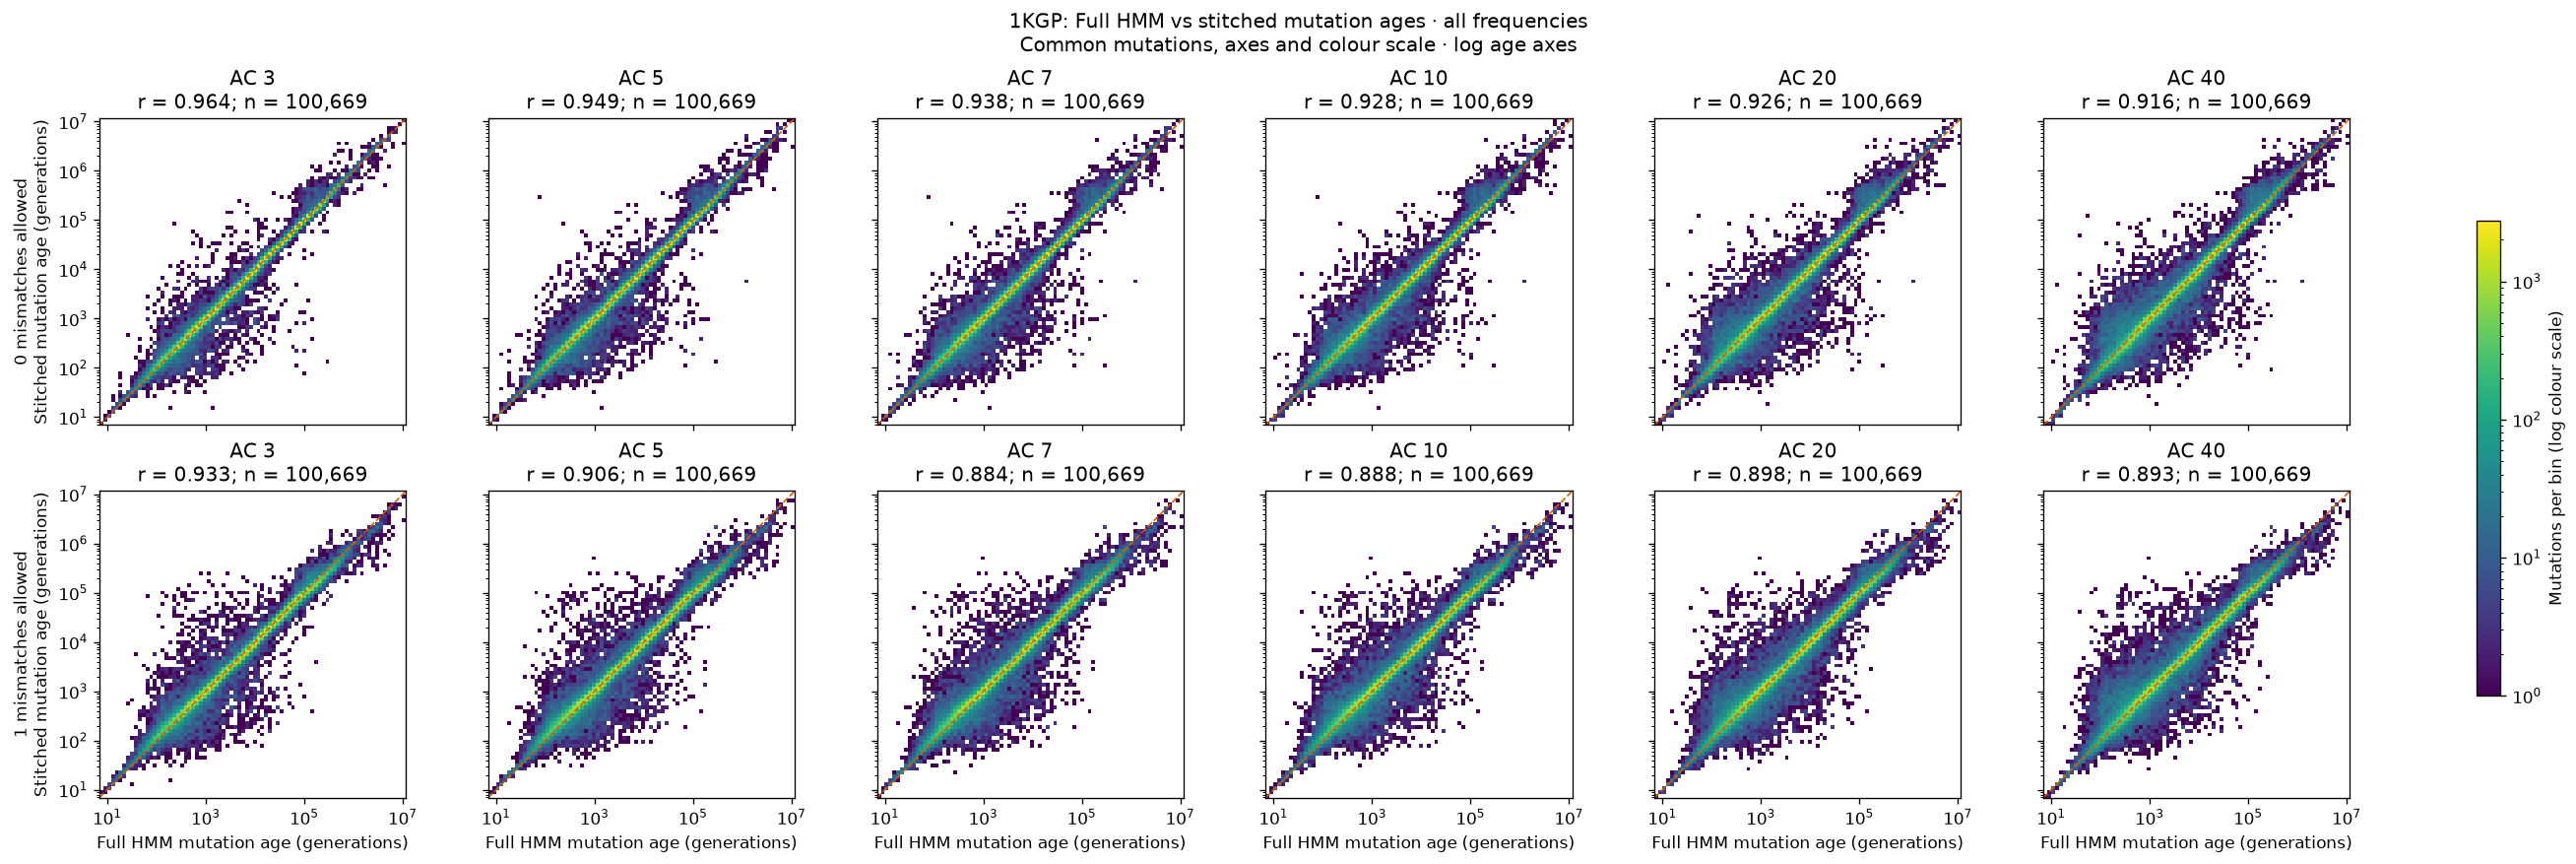

In [5]:
if __name__ == "__main__":
    stitched_age_pairs = nb_utils.stitched_mutation_age_pairs(dated_runs, config_path)
    for dataset in config["datasets"]:
        if dataset["name"] in config["dating"]["compare_full_datasets"]:
            fig = nb_plot.stitched_age_density_figure(
                stitched_age_pairs,
                config,
                experiment,
                dataset,
                age_scale="log",
                bins=80,
                cmap="viridis",
                colorbar_shrink=0.7,
                column_label="AC {value:g}",
                curve_label="{value} mismatches allowed",
                curve_parameter="max_mismatches",
                identity_color="#D55E00",
                panel_size=3.6,
                x_parameter="ac_cutoff",
            )
            nb_plot.save_figure(
                fig, f"mutation_age_density_{dataset['name']}", output_dir=output_dir
            )